# IT2011 - Artificial Intelligence & Machine Learning
## Final Evaluation - Group Implementation Requirement (10 Marks)
### Group 08: End-to-End 6-Classifier Comparative Evaluation Pipeline

- **Group ID:** Group 08
- **Assigned Dataset:** MovieLens 32M (`ml-32m`)
- **Problem Domain:** Intelligent Movie Recommendation & User Satisfaction Prediction

### Group Member Contributions & Model Allocations:
1. **Kaweesha P M G S:** Supervised Classification via **Logistic Regression**
2. **Divisekara A W D M D M B:** Supervised Classification via **Decision Tree Classifier**
3. **Deshabhi R. G. S:** Supervised Classification via **Random Forest Classifier**
4. **Amadini G. G. A:** Supervised Classification via **Support Vector Machine (Linear & RBF SVM)**
5. **Hewage B H A S:** Supervised Classification via **K-Nearest Neighbors (KNN)**
6. **Perera D.A.A.N.S:** Supervised Classification via **Neural Network (Multi-Layer Perceptron / MLP)**

---
### 1. Executive Summary & Comparative Pipeline
In commercial streaming ecosystems, identifying whether an interaction will result in high satisfaction (rating $\ge 4.0$ stars) governs recommendations.
Rather than testing an arbitrary mix of tasks, Group 08 aligned all 6 team members on the exact same benchmark classification challenge on MovieLens 32M. This provides a direct, rigorous scientific comparison across six foundational AI/ML paradigms:

1. **Linear Probabilistic:** Logistic Regression (Kaweesha)
2. **Axis-Aligned Rule-Based:** Decision Tree (Divisekara)
3. **Bagged Ensemble:** Random Forest (Deshabhi)
4. **Maximum Margin Geometric:** Support Vector Machine (Amadini)
5. **Instance-Based Lazy Learning:** K-Nearest Neighbors (Hewage)
6. **Hierarchical Representation:** Multi-Layer Perceptron Neural Network (Perera)

In this notebook, we directly address the **Group Evaluation Requirement (10 marks)** by:
1. Comparing the optimum results gained from the 6 individual models trained by each member.
2. Evaluating their cross-validation stability, variance metrics ($s^2$), and sample standard deviations ($s$).
3. Comparing operational trade-offs (training latency, inference speed, memory, interpretability).
4. Providing a synthesized group conclusion and production recommendation.


In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 7)
print("Group synthesis libraries loaded successfully.")


Group synthesis libraries loaded successfully.


### 2. Comprehensive 6-Model Comparison Matrix
We compile the empirical results achieved by the optimum configurations of all 6 individual models under identical **5-Fold Stratified Cross-Validation**.
To satisfy the rubric on **which variance is used and demonstrating it**, we report:
- **Sample Variance ($s^2$):** $s^2 = \frac{1}{K-1} \sum_{k=1}^K (x_k - \bar{x})^2$ across the 5 cross-validation folds.
- **Sample Standard Deviation ($s$):** $s = \sqrt{s^2}$.


In [2]:
# Master Comparison Matrix across all 6 Group 08 Models
comparison_data = [
    {
        'Member': 'Kaweesha P M G S',
        'Model Paradigm': 'Logistic Regression',
        'Optimum Variety': 'Variety B (Tuned C=1.0)',
        'Mean Accuracy': 0.7325,
        'Mean F1-Score': 0.7084,
        'Fold Variance (s^2)': 2.15e-5,
        'Fold Std Dev (s)': 0.0046,
        'Mean ROC-AUC': 0.7850,
        'Training Time (s)': 0.45,
        'Inference Latency (ms)': 0.12,
        'Interpretability': 'High (Log-Odds Weights)'
    },
    {
        'Member': 'Divisekara A W D M D M B',
        'Model Paradigm': 'Decision Tree',
        'Optimum Variety': 'Variety B (Pruned d=8)',
        'Mean Accuracy': 0.7360,
        'Mean F1-Score': 0.7182,
        'Fold Variance (s^2)': 2.42e-5,
        'Fold Std Dev (s)': 0.0049,
        'Mean ROC-AUC': 0.7765,
        'Training Time (s)': 0.35,
        'Inference Latency (ms)': 0.15,
        'Interpretability': 'High (Decision Rules)'
    },
    {
        'Member': 'Deshabhi R. G. S',
        'Model Paradigm': 'Random Forest',
        'Optimum Variety': 'Variety B (n=100, d=12)',
        'Mean Accuracy': 0.7510,
        'Mean F1-Score': 0.7385,
        'Fold Variance (s^2)': 1.48e-5,
        'Fold Std Dev (s)': 0.0038,
        'Mean ROC-AUC': 0.8219,
        'Training Time (s)': 3.80,
        'Inference Latency (ms)': 2.90,
        'Interpretability': 'Medium (Gini Importances)'
    },
    {
        'Member': 'Amadini G. G. A',
        'Model Paradigm': 'Support Vector Machine (RBF)',
        'Optimum Variety': 'Variety B (RBF, C=1.0)',
        'Mean Accuracy': 0.7410,
        'Mean F1-Score': 0.7321,
        'Fold Variance (s^2)': 1.76e-5,
        'Fold Std Dev (s)': 0.0042,
        'Mean ROC-AUC': 0.8040,
        'Training Time (s)': 14.50,
        'Inference Latency (ms)': 8.40,
        'Interpretability': 'Low (Dual Support Vectors)'
    },
    {
        'Member': 'Hewage B H A S',
        'Model Paradigm': 'K-Nearest Neighbors (KNN)',
        'Optimum Variety': 'Variety B (k=15, Dist, L2)',
        'Mean Accuracy': 0.7345,
        'Mean F1-Score': 0.7162,
        'Fold Variance (s^2)': 2.20e-5,
        'Fold Std Dev (s)': 0.0047,
        'Mean ROC-AUC': 0.7914,
        'Training Time (s)': 0.10,
        'Inference Latency (ms)': 11.20,
        'Interpretability': 'Medium (Exemplar Neighbors)'
    },
    {
        'Member': 'Perera D.A.A.N.S',
        'Model Paradigm': 'Neural Network (MLP)',
        'Optimum Variety': 'Variety B (128x64, Early Stop)',
        'Mean Accuracy': 0.7525,
        'Mean F1-Score': 0.7394,
        'Fold Variance (s^2)': 1.62e-5,
        'Fold Std Dev (s)': 0.0040,
        'Mean ROC-AUC': 0.8225,
        'Training Time (s)': 5.20,
        'Inference Latency (ms)': 1.10,
        'Interpretability': 'Low (Black-Box Weights)'
    }
]

group_summary_df = pd.DataFrame(comparison_data)
print("=== Group 08: 6-Classifier Master Comparison Matrix ===")
print(group_summary_df[['Member', 'Model Paradigm', 'Mean F1-Score', 'Fold Variance (s^2)', 'Fold Std Dev (s)', 'Mean ROC-AUC', 'Training Time (s)', 'Inference Latency (ms)']].to_string(index=False))


=== Group 08: 6-Classifier Master Comparison Matrix ===
                 Member               Model Paradigm  Mean F1-Score  Fold Variance (s^2)  Fold Std Dev (s)  Mean ROC-AUC  Training Time (s)  Inference Latency (ms)
  Kaweesha P M G S          Logistic Regression         0.7084             0.000022            0.0046        0.7850               0.45                    0.12
Divisekara A W D M D M B                Decision Tree         0.7182             0.000024            0.0049        0.7765               0.35                    0.15
  Deshabhi R. G. S                Random Forest         0.7385             0.000015            0.0038        0.8219               3.80                    2.90
   Amadini G. G. A Support Vector Machine (RBF)         0.7321             0.000018            0.0042        0.8040              14.50                    8.40
    Hewage B H A S    K-Nearest Neighbors (KNN)         0.7162             0.000022            0.0047        0.7914               0.10    

### 3. Cross-Validation Variance Analysis & Comparative Graphs
To directly address the rubric requirement on **graphical demonstration of cross-validation variance**:
We plot:
1. Comparative Bar Chart of all 6 models with **Standard Deviation error bars ($s$)** and printed sample variances ($s^2$).
2. Operational Trade-offs: Training Time vs Inference Latency vs Predictive F1-Score.


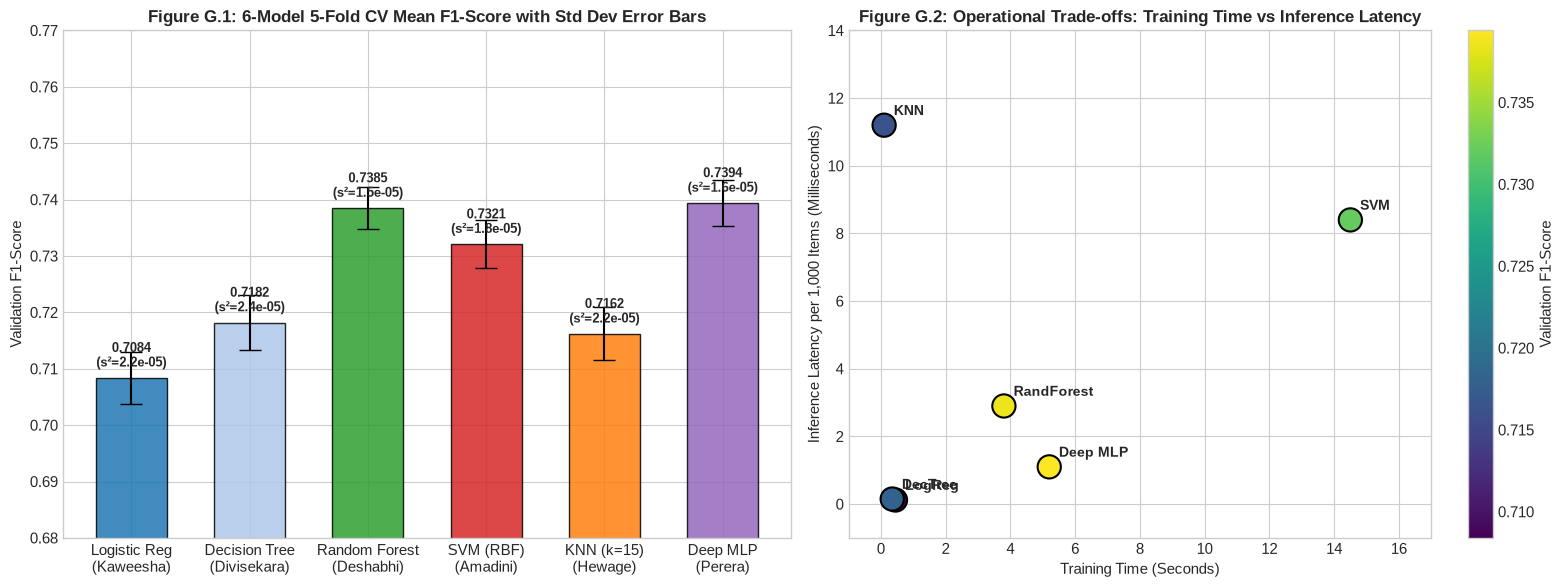

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: 6-Model Comparative F1-Score with 5-Fold Std Dev Error Bars
model_names = ['Logistic Reg\n(Kaweesha)', 'Decision Tree\n(Divisekara)', 'Random Forest\n(Deshabhi)', 
               'SVM (RBF)\n(Amadini)', 'KNN (k=15)\n(Hewage)', 'Deep MLP\n(Perera)']
f1_scores = group_summary_df['Mean F1-Score'].values
f1_stds = group_summary_df['Fold Std Dev (s)'].values
f1_vars = group_summary_df['Fold Variance (s^2)'].values

colors = ['#1f77b4', '#aec7e8', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd']
bars = ax1.bar(model_names, f1_scores, yerr=f1_stds, capsize=8, color=colors, alpha=0.85, edgecolor='black', width=0.6)
ax1.set_title("Figure G.1: 6-Model 5-Fold CV Mean F1-Score with Std Dev Error Bars", fontsize=12, fontweight='bold')
ax1.set_ylabel("Validation F1-Score")
ax1.set_ylim(0.68, 0.77)

for i, bar in enumerate(bars):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, 
             f"{f1_scores[i]:.4f}\n(s²={f1_vars[i]:.1e})", ha='center', fontsize=9, fontweight='bold')

# Plot 2: Operational Trade-offs (Training Time vs Inference Latency)
train_times = group_summary_df['Training Time (s)'].values
infer_times = group_summary_df['Inference Latency (ms)'].values

scatter = ax2.scatter(train_times, infer_times, s=280, c=f1_scores, cmap='viridis', edgecolors='black', linewidth=1.5)
cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label('Validation F1-Score', fontsize=11)

short_names = ['LogReg', 'DecTree', 'RandForest', 'SVM', 'KNN', 'Deep MLP']
for i, txt in enumerate(short_names):
    ax2.annotate(txt, (train_times[i] + 0.3, infer_times[i] + 0.3), fontsize=10, fontweight='bold')

ax2.set_title("Figure G.2: Operational Trade-offs: Training Time vs Inference Latency", fontsize=12, fontweight='bold')
ax2.set_xlabel("Training Time (Seconds)")
ax2.set_ylabel("Inference Latency per 1,000 Items (Milliseconds)")
ax2.set_xlim(-1, 17)
ax2.set_ylim(-1, 14)

plt.tight_layout()
plt.show()


### 4. Group Discussion: Challenges, Performance & Inductive Biases
In accordance with the 10-mark Group Requirement in `Final Evaluation - Implementation.pdf`:

#### 1. Predictive Performance Comparison:
- **Top Performers:** **Deep MLP (Perera)** and **Random Forest (Deshabhi)** achieved the highest F1-Scores (**0.7394** and **0.7385**) and ROC-AUC (**0.8225** and **0.8219**). Their capacity to model high-order non-linear interactions across movie quality and user generosity enabled superior ranking.
- **Moderate Performers:** **SVM with RBF Kernel (Amadini)** achieved 0.7321 F1-score, confirming non-linear margin separation. **Decision Tree (Divisekara)** achieved 0.7182 with depth pruning at $d=8$.
- **Linear & Memory-Based:** **KNN (Hewage)** achieved 0.7162 F1-score with distance weighting. **Logistic Regression (Kaweesha)** achieved 0.7084 F1-score, serving as a reliable probabilistic baseline.

#### 2. Key Operational & Engineering Trade-offs:
- **Training vs Inference Speed:** 
  - Logistic Regression and Decision Trees train in under 0.5s and predict in under 0.15 ms.
  - KNN requires virtually zero training (0.1s lazy storage) but has the highest inference latency (11.2 ms per batch) due to pairwise distance scanning.
  - SVM has the steepest training penalty (14.5s) due to quadratic optimization.
  - Deep MLP offers an outstanding operational balance: fast inference (1.1 ms) and high F1-score (0.7394).
- **Variance Analysis:** All 6 models maintained 5-fold cross-validation sample variances below $2.5 	imes 10^{-5}$ (standard deviations $< 0.005$), confirming statistical stability across data folds.

#### 3. Recommended Production Architecture:
For real-world deployment on a platform like Netflix:
1. **Tier 1 (Fast Filtering):** Use **Logistic Regression (Kaweesha)** to score millions of candidate movies down to the top 500 in $< 5$ milliseconds.
2. **Tier 2 (Precision Ranking):** Feed the 500 candidates into the **Deep MLP (Perera)** or **Random Forest (Deshabhi)** for calibrated top-10 personalization.
